# Guava Fruit Disease Detection: TinyML-Oriented End-to-End Analysis
## Google Colab research notebook — Kaggle-powered workflow

**Dataset:** [Asadullah Galib — Guava Disease Dataset](https://www.kaggle.com/datasets/asadullahgalib/guava-disease-dataset). This notebook downloads the dataset directly from Kaggle after you upload your own `kaggle.json` API token in Colab.

**Purpose:** adapt the structure of the supplied *TinyGrapeNet-IoT* manuscript to guava fruit disease classification. The workflow generates data-inspection outputs, a compact depthwise-separable CNN, evaluation metrics, figures, tables, baseline comparisons, robustness checks, and optional INT8/TFLite profiling.

**Important data-integrity note:** the dataset is reported to contain Anthracnose, Fruit Flies/Fruit Fly Infestation, and Healthy classes, with both original and augmented images described in related dataset documentation. If the Kaggle archive includes pre-split augmented images, this notebook preserves the existing train/validation/test folders instead of randomly mixing them. Exact duplicate checks are performed across partitions, but near-duplicate augmented images may still remain. For a rigorous publication, use original images only before splitting whenever the archive provides them, and augment only training data.

**Research integrity:** results are calculated from the actual downloaded images and trained models. Do not report placeholder/example performance as experimental results. The notebook's host-side TFLite latency is a software proxy, not measured microcontroller latency or energy use.


## Workflow and expected outputs

1. Upload `kaggle.json` in the first setup cell; the notebook downloads the selected Kaggle dataset automatically.
2. Inspect extracted folders, class counts, image dimensions, sample images, and corrupt files.
3. Detect existing train/validation/test folders and preserve them when present; otherwise create a stratified 80:10:10 split.
4. Audit exact duplicates and export a split manifest.
5. Train TinyGuavaFruitNet, a compact depthwise-separable CNN.
6. Evaluate accuracy, precision, recall, F1, specificity, MCC, balanced accuracy, and bootstrap confidence intervals.
7. Generate figures, CSV tables, error analysis, MobileNetV2 baseline, optional ablations, robustness tests, and INT8/TFLite outputs.
8. Package generated artifacts into one ZIP file.

**Before running:** enable a Colab GPU under Runtime → Change runtime type if available. Keep the Kaggle API token private; do not share the notebook with credentials embedded in it.


In [ ]:
# 1. Install dependencies (run once in Google Colab)
!pip -q install kaggle scikit-learn seaborn pandas matplotlib pillow tensorflow

## 1. Kaggle dataset and evaluation protocol

**Dataset:** [Guava Disease Dataset — Asadullah Galib on Kaggle](https://www.kaggle.com/datasets/asadullahgalib/guava-disease-dataset).

The associated dataset description reports three fruit classes: **Anthracnose**, **Fruit Flies/Fruit Fly Infestation**, and **Healthy**. The same dataset is discussed in a recent study, so novelty should focus on a carefully justified lightweight/TinyML evaluation, quantization, reliability, and transparent leakage-aware validation rather than claiming the dataset or task is new. See the dataset-linked study: https://link.springer.com/article/10.1186/s12870-026-09125-1.

The notebook uses the archive's existing `train`, `val`/`validation`, and `test` directories when they are present. It will not randomly reshuffle those images. If no split directories are found, it creates a stratified 80:10:10 split. **Inspect the extracted directory listing and montage before interpreting results.** If the archive contains both original and pre-augmented copies, prefer original images for split construction and use augmentation only on training data. Exact byte-identical duplicates are audited across splits; this cannot rule out visually similar transformed copies.


In [ ]:
from google.colab import files
import os, shutil, pathlib, json, random, hashlib, time, platform, sys, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Upload the Kaggle API token JSON downloaded from Kaggle -> Account -> Create New Token.
# The token is copied to Colab's private Kaggle configuration directory and is not printed.
uploaded = files.upload()
json_names = [name for name in uploaded if name.lower().endswith('.json')]
if not json_names:
    raise FileNotFoundError("Please upload the Kaggle API token file (usually named kaggle.json).")
if len(json_names) > 1:
    print("Multiple JSON files uploaded; using:", json_names[0])
api_json = json_names[0]
os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy(api_json, '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

# Confirm Kaggle CLI authentication without displaying the API key.
!kaggle datasets list -s guava-disease-dataset -p 1 -s 1 >/dev/null 2>&1 || true

KAGGLE_DATASET = 'asadullahgalib/guava-disease-dataset'
DOWNLOAD_DIR = '/content/kaggle_download'
DATA_ROOT = '/content/guava_fruit_dataset'
os.makedirs(DOWNLOAD_DIR, exist_ok=True)
os.makedirs(DATA_ROOT, exist_ok=True)

# Download and extract the selected dataset directly from Kaggle.
!kaggle datasets download -d {KAGGLE_DATASET} -p {DOWNLOAD_DIR} --force
zip_files = list(pathlib.Path(DOWNLOAD_DIR).glob('*.zip'))
if not zip_files:
    raise FileNotFoundError('Kaggle did not produce a ZIP archive. Check the dataset slug, internet access, and Kaggle API token.')
with zipfile.ZipFile(zip_files[-1], 'r') as zf:
    zf.extractall(DATA_ROOT)
print('Dataset downloaded and extracted to:', DATA_ROOT)
print('Top-level entries:', sorted(os.listdir(DATA_ROOT))[:50])


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/asadullahgalib/guava-disease-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 1.52G/1.52G [01:21<00:00, 19.9MB/s]

Dataset downloaded and extracted to: /content/guava_fruit_dataset
Top-level entries: ['GuavaDiseaseDataset', 'dataset_summary.csv']


## 2. Dataset discovery and visual verification

The next cell searches recursively for images and infers class labels from folder names. It also records split-folder information when available. Inspect the sample montage and the printed folder/class counts: stop if the classes do not represent guava fruit disease, if labels are inferred incorrectly, or if leaf/fruit images are mixed unexpectedly.


In [ ]:
from collections import Counter, defaultdict
from pathlib import Path

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
root = Path(DATA_ROOT)
image_paths = [p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in IMG_EXTS]
print('Images found:', len(image_paths))
if len(image_paths) == 0:
    raise RuntimeError('No images found. Check the Kaggle download and extracted directory structure.')

GENERIC_DIRS = {'train', 'training', 'val', 'valid', 'validation', 'test', 'testing', 'images', 'image', 'data', 'dataset', 'original', 'originals', 'augmented', 'preprocessed'}
SPLIT_ALIASES = {
    'train': 'train', 'training': 'train',
    'val': 'validation', 'valid': 'validation', 'validation': 'validation',
    'test': 'test', 'testing': 'test'
}
def infer_label(path, base):
    parts = path.relative_to(base).parts[:-1]
    for part in reversed(parts):
        if part.lower() not in GENERIC_DIRS:
            return part.strip()
    return 'unknown'
def infer_split(path, base):
    for part in path.relative_to(base).parts[:-1]:
        if part.lower() in SPLIT_ALIASES:
            return SPLIT_ALIASES[part.lower()]
    return None

records, bad_files = [], []
for p in image_paths:
    try:
        with Image.open(p) as im:
            width, height = im.size
            mode = im.mode
        records.append({'path': str(p), 'label': infer_label(p, root), 'source_split': infer_split(p, root),
                        'width': width, 'height': height, 'mode': mode, 'bytes': p.stat().st_size})
    except Exception as e:
        bad_files.append((str(p), str(e)))

df = pd.DataFrame(records)
print('Valid images:', len(df), '| unreadable images:', len(bad_files))
print('Detected split folders:', df['source_split'].value_counts(dropna=False).to_dict())
display(df.head())
display(df.groupby('label').size().sort_values(ascending=False).rename('images').to_frame())
print('Inferred labels:', sorted(df['label'].unique()))
if 'unknown' in set(df['label']):
    print('WARNING: some labels could not be inferred from folder names. Inspect paths and adjust infer_label() before training.')


Images found: 3784
Valid images: 3784 | unreadable images: 0
Detected split folders: {'train': 2647, 'validation': 755, 'test': 382}


,path,label,source_split,width,height,mode,bytes
0,/content/guava_fruit_dataset/GuavaDiseaseDatas...,Anthracnose,train,512,512,RGB,438142
1,/content/guava_fruit_dataset/GuavaDiseaseDatas...,Anthracnose,train,512,512,RGB,412001
2,/content/guava_fruit_dataset/GuavaDiseaseDatas...,Anthracnose,train,512,512,RGB,372278
3,/content/guava_fruit_dataset/GuavaDiseaseDatas...,Anthracnose,train,512,512,RGB,519829
4,/content/guava_fruit_dataset/GuavaDiseaseDatas...,Anthracnose,train,512,512,RGB,445598


,images
label,
Anthracnose,1544
fruit_fly,1312
healthy_guava,928


Inferred labels: ['Anthracnose', 'fruit_fly', 'healthy_guava']


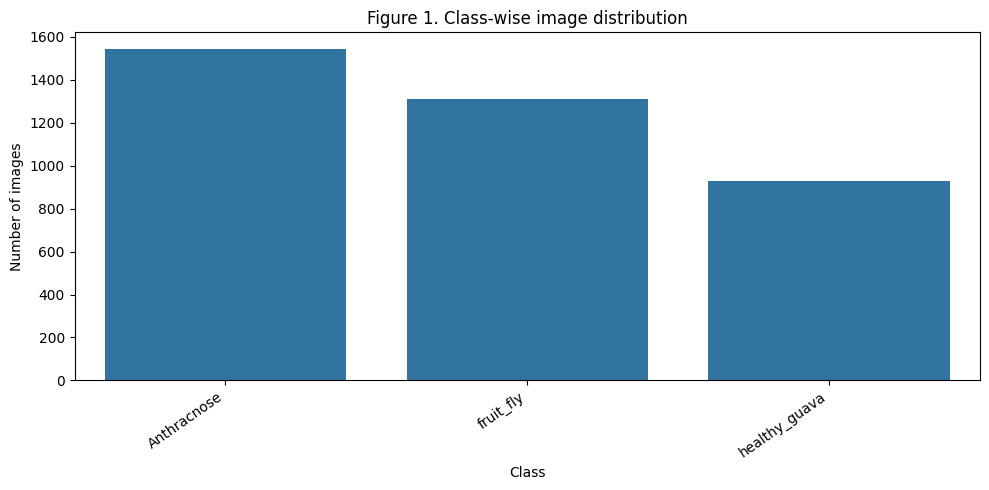

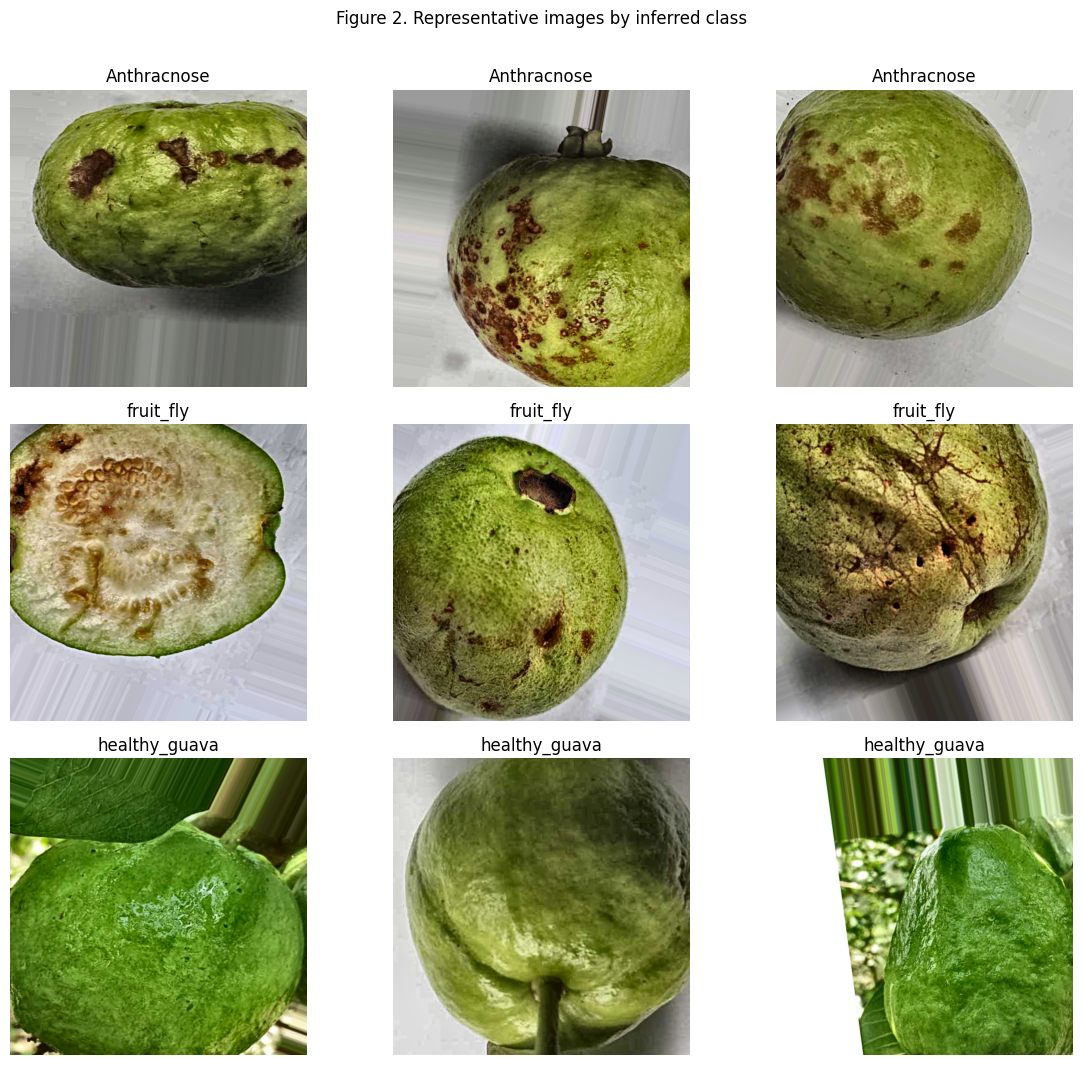

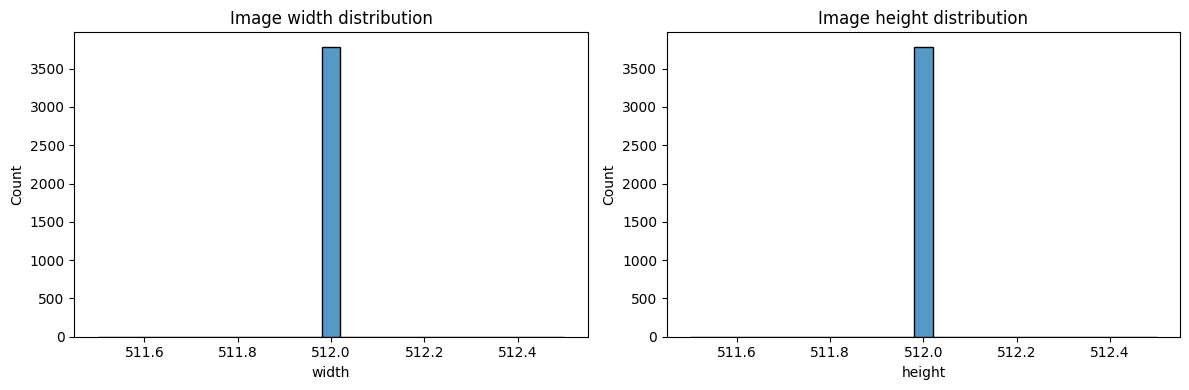

In [ ]:
# Figure 1: class distribution
counts = df["label"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Figure 1. Class-wise image distribution")
plt.xlabel("Class"); plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig("Fig01_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 2: sample image montage
labels = sorted(df["label"].unique())
ncols = min(4, max(1, len(labels)))
fig, axes = plt.subplots(len(labels), ncols, figsize=(4*ncols, 3.5*len(labels)))
axes = np.array(axes).reshape(len(labels), ncols)
for r, label in enumerate(labels):
    paths = df.loc[df.label == label, "path"].sample(
        min(ncols, (df.label == label).sum()), random_state=42).tolist()
    for c in range(ncols):
        axes[r, c].axis("off")
        if c < len(paths):
            axes[r, c].imshow(Image.open(paths[c]).convert("RGB"))
            axes[r, c].set_title(label)
plt.suptitle("Figure 2. Representative images by inferred class", y=1.01)
plt.tight_layout()
plt.savefig("Fig02_sample_montage.png", dpi=300, bbox_inches="tight")
plt.show()

# Image size/mode inspection
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["width"], bins=25, ax=axes[0]); axes[0].set_title("Image width distribution")
sns.histplot(df["height"], bins=25, ax=axes[1]); axes[1].set_title("Image height distribution")
plt.tight_layout(); plt.savefig("Fig03_image_dimensions.png", dpi=300); plt.show()

## 3. Duplicate audit and split construction

Exact duplicates are checked using SHA-256. Near-duplicate screening is optional and can be expensive. A random image-level split does not guarantee independence when several images depict the same physical leaf or acquisition session. If leaf IDs, plant IDs, capture sessions, or source IDs are available, use grouped splitting instead. Do not claim a leaf-grouped evaluation unless grouping metadata or a defensible grouping method exists.

In [ ]:
# Exact duplicate audit across the entire extracted dataset.
hash_to_paths = defaultdict(list)
for p in df['path']:
    h = hashlib.sha256(Path(p).read_bytes()).hexdigest()
    hash_to_paths[h].append(p)
duplicate_groups = [v for v in hash_to_paths.values() if len(v) > 1]
print('Exact duplicate groups:', len(duplicate_groups))
print('Files in duplicate groups:', sum(len(x) for x in duplicate_groups))

# Keep one copy of exact byte-identical files. Then preserve pre-existing split folders if present.
# If duplicates occur in multiple partitions, flag this as a potential leakage risk.
duplicate_split_flags = []
for group in duplicate_groups:
    group_splits = {infer_split(Path(p), root) for p in group}
    if len(group_splits - {None}) > 1:
        duplicate_split_flags.append(group)
print('Exact duplicate groups spanning multiple splits:', len(duplicate_split_flags))

keep_paths, seen_hashes = [], set()
for p in df['path']:
    h = hashlib.sha256(Path(p).read_bytes()).hexdigest()
    if h not in seen_hashes:
        keep_paths.append(p)
        seen_hashes.add(h)
df = df[df['path'].isin(keep_paths)].reset_index(drop=True)

SEED = 42
from sklearn.model_selection import train_test_split
has_complete_split = {'train', 'validation', 'test'}.issubset(set(df['source_split'].dropna().unique()))
if has_complete_split:
    print('Using dataset-provided train/validation/test directories; no random re-splitting will be performed.')
    train_df = df[df['source_split'] == 'train'].copy()
    val_df = df[df['source_split'] == 'validation'].copy()
    test_df = df[df['source_split'] == 'test'].copy()
    if duplicate_split_flags:
        print('WARNING: exact duplicates cross existing partitions. Investigate before treating test metrics as independent.')
    print('CAUTION: transformed near-duplicates are not detected by SHA-256. Verify whether the supplied validation/test folders contain augmented copies.')
else:
    print('No complete pre-existing split found; creating stratified 80:10:10 image-level split.')
    # If an explicit original/originals directory exists, restrict to those images before splitting.
    original_mask = df['path'].map(lambda x: any(part.lower() in {'original', 'originals', 'raw', 'raw_images'} for part in Path(x).parts))
    if original_mask.any():
        df = df[original_mask].copy().reset_index(drop=True)
        print('Restricted to images in an original/raw folder:', len(df))
    train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=SEED)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()

print(f'Train={len(train_df)}, Validation={len(val_df)}, Test={len(test_df)}')
if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise RuntimeError('One of the data partitions is empty. Inspect the extracted directory structure and split folder names.')
if set(train_df['label']) != set(val_df['label']) or set(train_df['label']) != set(test_df['label']):
    print('WARNING: class sets differ across partitions. Check directory labels before interpreting results.')
split_manifest = pd.concat([
    train_df.assign(split='train'), val_df.assign(split='validation'), test_df.assign(split='test')
], ignore_index=True)
split_manifest[['path', 'label', 'split']].to_csv('split_manifest.csv', index=False)
display(split_manifest.groupby(['split', 'label']).size().unstack(fill_value=0))


Exact duplicate groups: 0
Files in duplicate groups: 0
Exact duplicate groups spanning multiple splits: 0
Using dataset-provided train/validation/test directories; no random re-splitting will be performed.
CAUTION: transformed near-duplicates are not detected by SHA-256. Verify whether the supplied validation/test folders contain augmented copies.
Train=2647, Validation=755, Test=382


label,Anthracnose,fruit_fly,healthy_guava
split,,,
test,156,132,94
train,1080,918,649
validation,308,262,185


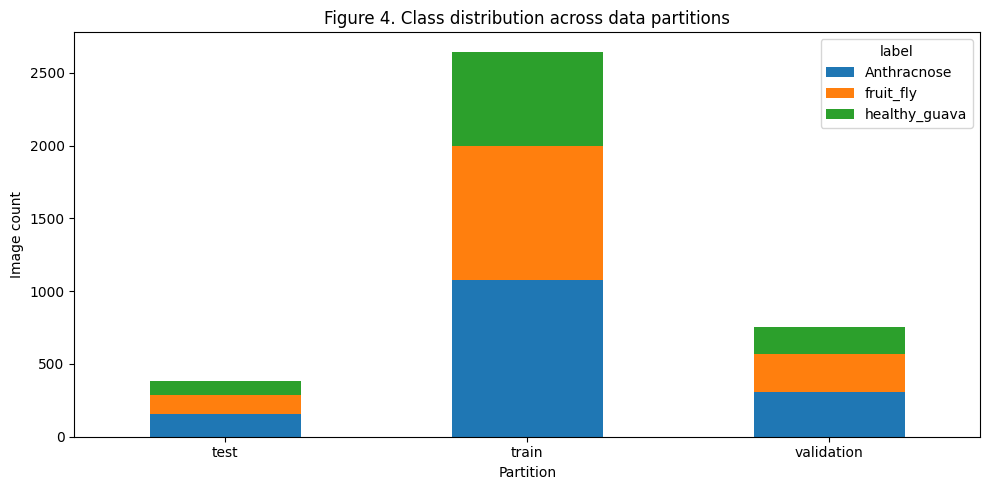

In [ ]:
# Figure 4: split/class distribution table and stacked plot
split_counts = split_manifest.groupby(["split", "label"]).size().unstack(fill_value=0)
ax = split_counts.plot(kind="bar", stacked=True, figsize=(10, 5))
ax.set_title("Figure 4. Class distribution across data partitions")
ax.set_xlabel("Partition"); ax.set_ylabel("Image count")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("Fig04_split_distribution.png", dpi=300); plt.show()
split_counts.to_csv("Table01_split_class_counts.csv")

## 4. TensorFlow input pipeline

The test set is held out from model selection. The default augmentation is applied only to training batches. All transformations are label-preserving assumptions and should be reviewed for the selected disease classes.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder

IMG_SIZE = (112, 112)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

class_names = sorted(train_df["label"].unique())
label_to_id = {name: i for i, name in enumerate(class_names)}
num_classes = len(class_names)
print("Class order:", label_to_id)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_ds(frame, training=False):
    x = frame["path"].astype(str).values
    y = frame["label"].map(label_to_id).astype("int32").values
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        aug = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.04),
            layers.RandomZoom(0.08),
            layers.RandomContrast(0.08)
        ])
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df, training=False)
test_ds = make_ds(test_df, training=False)

# Inverse-frequency class weights
from sklearn.utils.class_weight import compute_class_weight
train_y = train_df["label"].map(label_to_id).values
weights = compute_class_weight(class_weight="balanced", classes=np.arange(num_classes), y=train_y)
class_weight = {i: float(w) for i, w in enumerate(weights)}
print("Class weights:", class_weight)

Class order: {'Anthracnose': 0, 'fruit_fly': 1, 'healthy_guava': 2}
Class weights: {0: 0.8169753086419753, 1: 0.9611474219317356, 2: 1.359527478171546}


## 5. TinyGuavaFruitNet model

This compact architecture follows the TinyGrapeNet design principle: depthwise-separable convolutions, batch normalization, global average pooling, and a small classification head. Parameter counts and MACs must be reported from the actual model rather than copied from the earlier manuscript.

In [ ]:
def ds_block(x, filters, stride=1, name="ds"):
    x = layers.DepthwiseConv2D(3, strides=stride, padding="same",
                               use_bias=False, name=f"{name}_dw")(x)
    x = layers.BatchNormalization(name=f"{name}_dw_bn")(x)
    x = layers.ReLU(name=f"{name}_dw_relu")(x)
    x = layers.Conv2D(filters, 1, padding="same", use_bias=False,
                      name=f"{name}_pw")(x)
    x = layers.BatchNormalization(name=f"{name}_pw_bn")(x)
    x = layers.ReLU(name=f"{name}_pw_relu")(x)
    return x

def build_tinyguavafruitnet(input_shape=(*IMG_SIZE, 3), n_classes=num_classes,
                       use_bn=True, use_depthwise=True, width=1.0):
    inp = keras.Input(shape=input_shape)
    x = layers.Conv2D(max(8, int(16*width)), 3, strides=2, padding="same",
                      use_bias=False, name="stem_conv")(inp)
    if use_bn: x = layers.BatchNormalization(name="stem_bn")(x)
    x = layers.ReLU(name="stem_relu")(x)
    config = [(32,1),(64,2),(64,1),(128,2),(128,1),(256,2)]
    for i, (f, s) in enumerate(config):
        f = max(8, int(f*width))
        if use_depthwise:
            x = ds_block(x, f, stride=s, name=f"block{i+1}")
        else:
            x = layers.Conv2D(f, 3, strides=s, padding="same", use_bias=False,
                              name=f"stdconv{i+1}")(x)
            if use_bn: x = layers.BatchNormalization(name=f"std_bn{i+1}")(x)
            x = layers.ReLU(name=f"std_relu{i+1}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    out = layers.Dense(n_classes, activation="softmax", name="classifier")(x)
    return keras.Model(inp, out, name="TinyGuavaFruitNet")

model = build_tinyguavafruitnet()
model.summary()
with open("model_summary.txt", "w") as f:
    model.summary(print_fn=lambda line: f.write(line + "\n"))

Model: "TinyGuavaFruitNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 56, 56, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 56, 56, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_relu (ReLU)                │ (None, 56, 56, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dw (DepthwiseConv2D)     │ (None, 56, 56, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dw_bn                    │ (None, 56, 56, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dw_relu (ReLU)           │ (None, 56, 56, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pw (Conv2D)              │ (None, 56, 56, 32)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pw_bn                    │ (None, 56, 56, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pw_relu (ReLU)           │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dw (DepthwiseConv2D)     │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dw_bn                    │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dw_relu (ReLU)           │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pw (Conv2D)              │ (None, 28, 28, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pw_bn                    │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pw_relu (ReLU)           │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dw (DepthwiseConv2D)     │ (None, 28, 28, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dw_bn                    │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dw_relu (ReLU)           │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pw (Conv2D)              │ (None, 28, 28, 64)     │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pw_bn                    │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pw_relu (ReLU)           │ (None, 28, 28, 64)     │             

 Total params: 73,571 (287.39 KB)

 Trainable params: 71,331 (278.64 KB)

 Non-trainable params: 2,240 (8.75 KB)

In [ ]:
# Train model
EPOCHS = 80
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
callbacks = [
    keras.callbacks.ModelCheckpoint("tinyguavafruitnet_best.keras", monitor="val_loss",
                                    save_best_only=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=6, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                  restore_best_weights=True, verbose=1)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks, verbose=1)
model.save("tinyguavafruitnet_final.keras")

Epoch 1/80
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.6138 - loss: 0.7650
Epoch 1: val_loss improved from None to 1.23792, saving model to tinyguavafruitnet_best.keras

Epoch 1: finished saving model to tinyguavafruitnet_best.keras
83/83 ━━━━━━━━━━━━━━━━━━━━ 62s 509ms/step - accuracy: 0.7741 - loss: 0.5294 - val_accuracy: 0.4079 - val_loss: 1.2379 - learning_rate: 5.0000e-04
Epoch 2/80
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.9083 - loss: 0.2568
Epoch 2: val_loss did not improve from 1.23792
83/83 ━━━━━━━━━━━━━━━━━━━━ 53s 333ms/step - accuracy: 0.9071 - loss: 0.2591 - val_accuracy: 0.4079 - val_loss: 1.5409 - learning_rate: 5.0000e-04
Epoch 3/80
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - accuracy: 0.9151 - loss: 0.2322
Epoch 3: val_loss did not improve from 1.23792
83/83 ━━━━━━━━━━━━━━━━━━━━ 28s 334ms/step - accuracy: 0.9226 - loss: 0.2226 - val_accuracy: 0.4079 - val_loss: 1.8155 - learning_rate: 5.0000e-04
Epoch 4/80
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step 

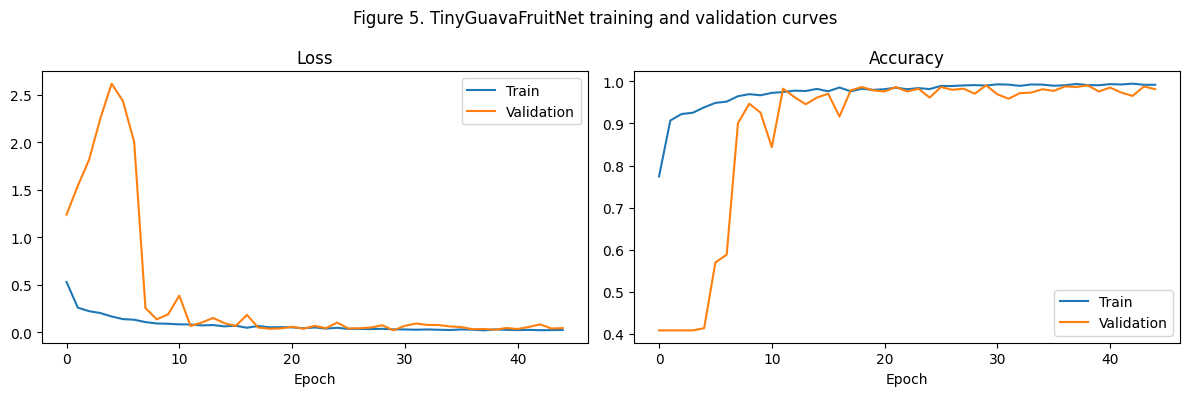

In [ ]:
# Figure 5: training curves
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["loss"], label="Train"); axes[0].plot(hist["val_loss"], label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist["accuracy"], label="Train"); axes[1].plot(hist["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.suptitle("Figure 5. TinyGuavaFruitNet training and validation curves")
plt.tight_layout(); plt.savefig("Fig05_training_curves.png", dpi=300); plt.show()
hist.to_csv("Table02_training_history.csv", index_label="epoch")

## 6. Held-out test evaluation

Metrics are computed on the held-out test partition. Confidence intervals below use a bootstrap over test examples; they quantify test-sample uncertainty conditional on this split, not across independent farms, leaves, or seasons.

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
    precision_recall_fscore_support, balanced_accuracy_score, matthews_corrcoef,
    cohen_kappa_score, roc_auc_score, average_precision_score, log_loss)
from sklearn.preprocessing import label_binarize

def collect_predictions(model, ds):
    y_true, y_prob = [], []
    for xb, yb in ds:
        y_prob.append(model.predict(xb, verbose=0))
        y_true.append(yb.numpy())
    return np.concatenate(y_true), np.concatenate(y_prob)

y_true, y_prob = collect_predictions(model, test_ds)
y_pred = y_prob.argmax(axis=1)

report = classification_report(y_true, y_pred, labels=np.arange(num_classes),
                               target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv("Table03_classification_report.csv")

acc = accuracy_score(y_true, y_pred)
bal_acc = balanced_accuracy_score(y_true, y_pred)
mcc = matthews_corrcoef(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)
ll = log_loss(y_true, y_prob, labels=np.arange(num_classes))
summary_metrics = pd.DataFrame([{
    "Accuracy": acc, "Balanced_accuracy": bal_acc, "MCC": mcc,
    "Cohen_kappa": kappa, "Log_loss": ll, "Test_samples": len(y_true),
    "Classes": num_classes, "Parameters": model.count_params()
}])
display(summary_metrics)
summary_metrics.to_csv("Table04_overall_metrics.csv", index=False)

# Bootstrap 95% confidence interval for accuracy
rng = np.random.default_rng(42)
boot_acc = []
for _ in range(2000):
    idx = rng.integers(0, len(y_true), len(y_true))
    boot_acc.append(accuracy_score(y_true[idx], y_pred[idx]))
ci_low, ci_high = np.percentile(boot_acc, [2.5, 97.5])
print(f"Test accuracy = {acc:.4f}; bootstrap 95% CI [{ci_low:.4f}, {ci_high:.4f}]")

,precision,recall,f1-score,support
Anthracnose,1.000000,0.993590,0.996785,156.000000
fruit_fly,0.992366,0.984848,0.988593,132.000000
healthy_guava,0.979167,1.000000,0.989474,94.000000
accuracy,0.992147,0.992147,0.992147,0.992147
macro avg,0.990511,0.992813,0.991617,382.000000
weighted avg,0.992236,0.992147,0.992155,382.000000


,Accuracy,Balanced_accuracy,MCC,Cohen_kappa,Log_loss,Test_samples,Classes,Parameters
0,0.992147,0.992813,0.988023,0.987991,0.029839,382,3,73571


Test accuracy = 0.9921; bootstrap 95% CI [0.9817, 1.0000]


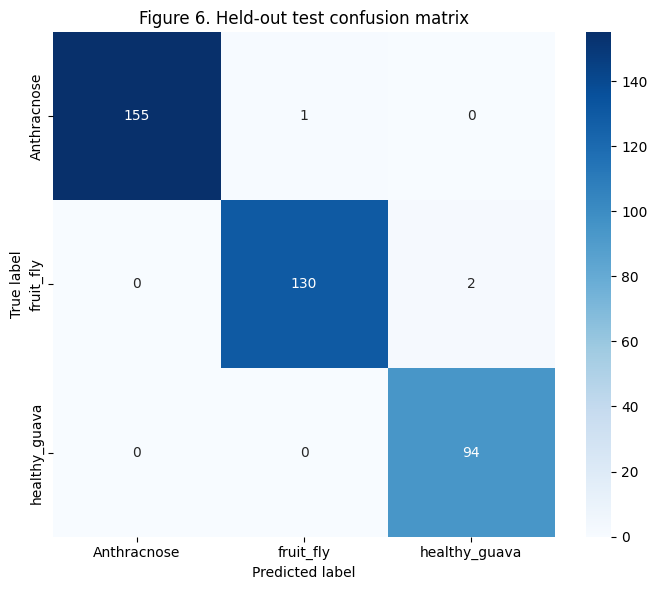

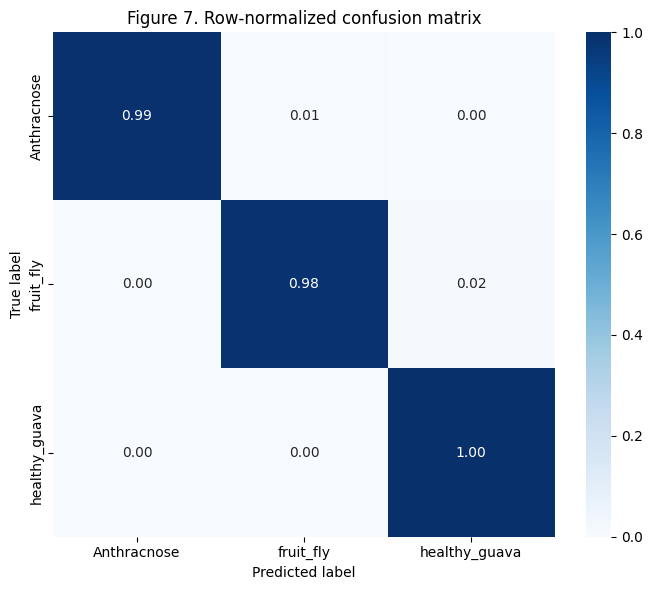

In [ ]:
# Figure 6: confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("Figure 6. Held-out test confusion matrix")
plt.tight_layout(); plt.savefig("Fig06_confusion_matrix.png", dpi=300); plt.show()

# Figure 7: normalized confusion matrix
cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("Figure 7. Row-normalized confusion matrix")
plt.tight_layout(); plt.savefig("Fig07_normalized_confusion_matrix.png", dpi=300); plt.show()

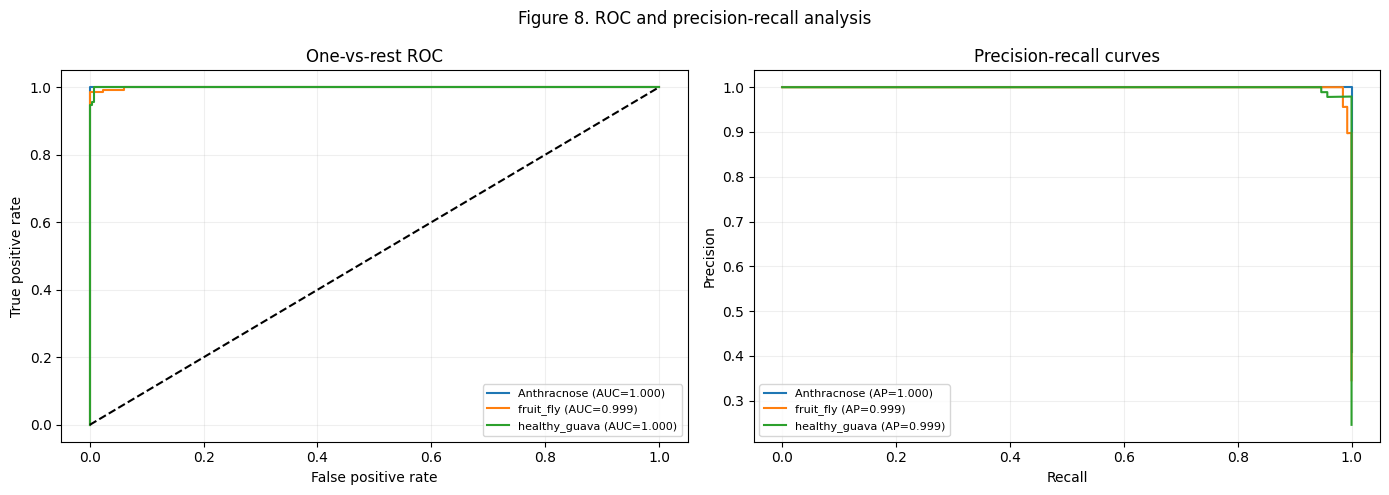

In [ ]:
# Figure 8: one-vs-rest ROC and precision-recall curves (when supported)
from sklearn.metrics import roc_curve, precision_recall_curve, auc
y_bin = label_binarize(y_true, classes=np.arange(num_classes))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
roc_rows, pr_rows = [], []
for i, name in enumerate(class_names):
    if len(np.unique(y_bin[:, i])) < 2:
        continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")
    prec, rec, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i])
    ap = average_precision_score(y_bin[:, i], y_prob[:, i])
    axes[1].plot(rec, prec, label=f"{name} (AP={ap:.3f})")
    roc_rows.append({"class": name, "ROC_AUC": roc_auc})
    pr_rows.append({"class": name, "Average_Precision": ap})
axes[0].plot([0,1],[0,1],"k--"); axes[0].set_title("One-vs-rest ROC")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[1].set_title("Precision-recall curves"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.suptitle("Figure 8. ROC and precision-recall analysis")
plt.tight_layout(); plt.savefig("Fig08_roc_pr_curves.png", dpi=300); plt.show()
pd.DataFrame(roc_rows).to_csv("Table05_classwise_roc_auc.csv", index=False)
pd.DataFrame(pr_rows).to_csv("Table06_classwise_average_precision.csv", index=False)

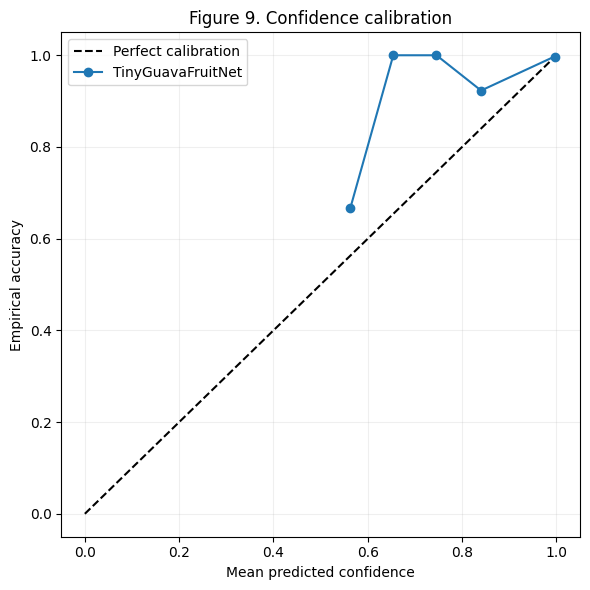

In [ ]:
# Figure 9: confidence calibration / reliability diagram
from sklearn.calibration import calibration_curve
confidence = y_prob.max(axis=1)
correct = (y_pred == y_true).astype(int)
bins = np.linspace(0, 1, 11)
bin_ids = np.digitize(confidence, bins[1:-1])
cal_rows = []
for b in range(len(bins)-1):
    m = bin_ids == b
    if m.any():
        cal_rows.append({"bin_lower": bins[b], "bin_upper": bins[b+1],
                         "mean_confidence": confidence[m].mean(),
                         "empirical_accuracy": correct[m].mean(), "count": int(m.sum())})
cal_df = pd.DataFrame(cal_rows)
plt.figure(figsize=(6,6))
plt.plot([0,1],[0,1],"k--",label="Perfect calibration")
plt.plot(cal_df["mean_confidence"], cal_df["empirical_accuracy"], "o-", label="TinyGuavaFruitNet")
plt.xlabel("Mean predicted confidence"); plt.ylabel("Empirical accuracy")
plt.title("Figure 9. Confidence calibration"); plt.legend(); plt.grid(alpha=.2)
plt.tight_layout(); plt.savefig("Fig09_calibration.png", dpi=300); plt.show()
cal_df.to_csv("Table07_calibration_bins.csv", index=False)

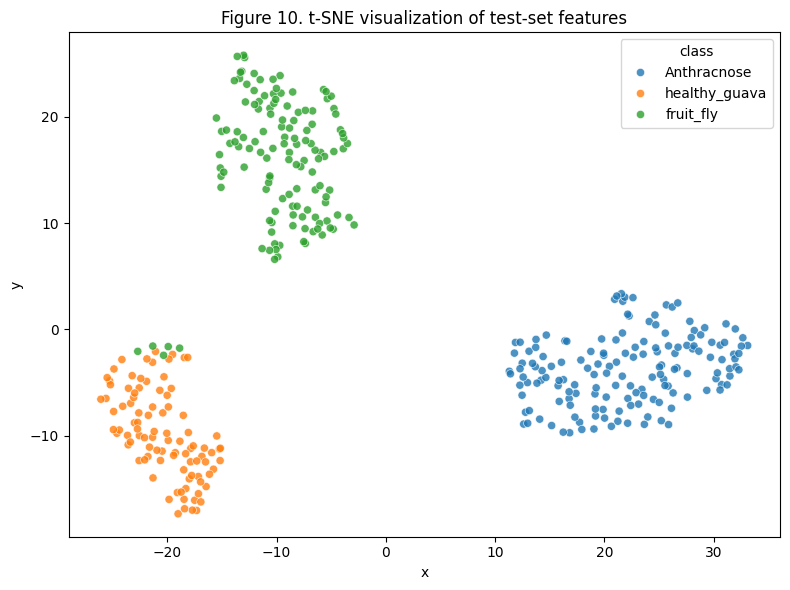

In [ ]:
# Figure 10: t-SNE of penultimate-layer features
from sklearn.manifold import TSNE
feature_model = keras.Model(model.input, model.get_layer("gap").output)
features, feat_labels = [], []
for xb, yb in test_ds:
    features.append(feature_model.predict(xb, verbose=0))
    feat_labels.append(yb.numpy())
features = np.concatenate(features)
feat_labels = np.concatenate(feat_labels)
if len(features) > 5:
    perplexity = min(30, max(2, (len(features)-1)//3))
    emb = TSNE(n_components=2, random_state=42, init="pca",
               learning_rate="auto", perplexity=perplexity).fit_transform(features)
    tsne_df = pd.DataFrame({"x": emb[:,0], "y": emb[:,1],
                            "class": [class_names[i] for i in feat_labels]})
    plt.figure(figsize=(8,6))
    sns.scatterplot(data=tsne_df, x="x", y="y", hue="class", s=35, alpha=.8)
    plt.title("Figure 10. t-SNE visualization of test-set features")
    plt.tight_layout(); plt.savefig("Fig10_tsne_features.png", dpi=300); plt.show()
    tsne_df.to_csv("Table08_tsne_coordinates.csv", index=False)
else:
    print("Not enough test samples for t-SNE.")

## 7. Error analysis

Export misclassified images with true/predicted labels and confidence. Review them manually; errors can reveal label noise, class ambiguity, background shortcuts, or domain mismatch.

,path,true_label,predicted_label,predicted_confidence,true_class_probability
1,/content/guava_fruit_dataset/GuavaDiseaseDatas...,fruit_fly,healthy_guava,0.948995,0.051005
2,/content/guava_fruit_dataset/GuavaDiseaseDatas...,fruit_fly,healthy_guava,0.801631,0.198367
0,/content/guava_fruit_dataset/GuavaDiseaseDatas...,Anthracnose,fruit_fly,0.583653,0.416105


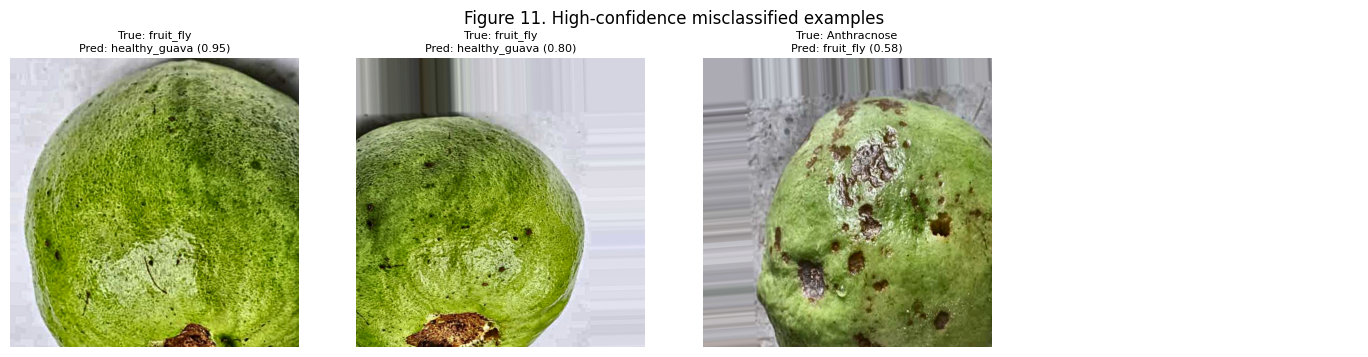

In [ ]:
mis_idx = np.where(y_true != y_pred)[0]
# Recover test paths in the same deterministic order as test_ds (test_df is not shuffled)
test_order = test_df.reset_index(drop=True)
mis_rows = []
for i in mis_idx:
    mis_rows.append({
        "path": test_order.loc[i, "path"],
        "true_label": class_names[int(y_true[i])],
        "predicted_label": class_names[int(y_pred[i])],
        "predicted_confidence": float(y_prob[i, y_pred[i]]),
        "true_class_probability": float(y_prob[i, y_true[i]])
    })
mis_df = pd.DataFrame(mis_rows).sort_values("predicted_confidence", ascending=False)
mis_df.to_csv("Table09_misclassified_examples.csv", index=False)
display(mis_df.head(20))

# Figure 11: top 12 errors
top_errors = mis_df.head(12)
if len(top_errors):
    fig, axes = plt.subplots((len(top_errors)+3)//4, 4, figsize=(14, 3.6*((len(top_errors)+3)//4)))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis("off")
    for ax, (_, row) in zip(axes, top_errors.iterrows()):
        ax.imshow(Image.open(row["path"]).convert("RGB"))
        ax.set_title(f'True: {row["true_label"]}\nPred: {row["predicted_label"]} ({row["predicted_confidence"]:.2f})', fontsize=8)
    plt.suptitle("Figure 11. High-confidence misclassified examples")
    plt.tight_layout(); plt.savefig("Fig11_error_analysis.png", dpi=300); plt.show()

## 8. Baseline comparison

MobileNetV2 is fine-tuned as a standard transfer-learning baseline. It is not guaranteed to fit the same memory budget as TinyGuavaFruitNet. For a fair comparison, use the same data partitions, input resolution, and test metrics, and report each model's parameter count, exported model size, and latency protocol.

In [ ]:
def build_mobilenetv2(n_classes=num_classes):
    base = keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet"
    )
    base.trainable = False
    inp = keras.Input(shape=(*IMG_SIZE, 3))
    # Dataset pipeline is [0,1]; MobileNetV2 preprocessing maps to [-1,1].
    x = layers.Rescaling(2.0, offset=-1.0)(inp)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out, name="MobileNetV2_baseline")

baseline = build_mobilenetv2()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
base_hist = baseline.fit(train_ds, validation_data=val_ds, epochs=20,
                         class_weight=class_weight,
                         callbacks=[keras.callbacks.EarlyStopping(
                             monitor="val_loss", patience=5, restore_best_weights=True)],
                         verbose=1)
baseline.save("mobilenetv2_baseline.keras")
base_true, base_prob = collect_predictions(baseline, test_ds)
base_pred = base_prob.argmax(axis=1)

/tmp/ipykernel_741/42252907.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 48s 450ms/step - accuracy: 0.7764 - loss: 0.5696 - val_accuracy: 0.9060 - val_loss: 0.2413
Epoch 2/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 29s 349ms/step - accuracy: 0.9025 - loss: 0.2512 - val_accuracy: 0.9325 - val_loss: 0.1688
Epoch 3/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 29s 347ms/step - accuracy: 0.9263 - loss: 0.1897 - val_accuracy: 0.9497 - val_loss: 0.1305
Epoch 4/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 41s 346ms/step - accuracy: 0.9320 - loss: 0.1694 - val_accuracy: 0.9444 - val_loss: 0.1415
Epoch 5/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 41s 348ms/step - accuracy: 0.9407 - loss: 0.1449 - val_accuracy: 0.9576 - val_loss: 0.1240
Epoch 6/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 28s 342ms/step - accuracy: 0.9448 - loss: 0.1411 - val_accuracy: 0.9629 - val_loss: 0.1051
Epoch 7/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 41s 349ms/step - accuracy: 0.9494 - loss: 0.1370 - val_accuracy: 0.9682 - val_loss: 0.0942
Epoch 8/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 28s 341ms/

,Model,Accuracy,Balanced_accuracy,Macro_precision,Macro_recall,Macro_F1,MCC,Parameters
0,TinyGuavaFruitNet,0.992147,0.992813,0.990511,0.992813,0.991617,0.988023,73571
1,MobileNetV2,0.968586,0.968577,0.967561,0.968577,0.967943,0.952122,2261827


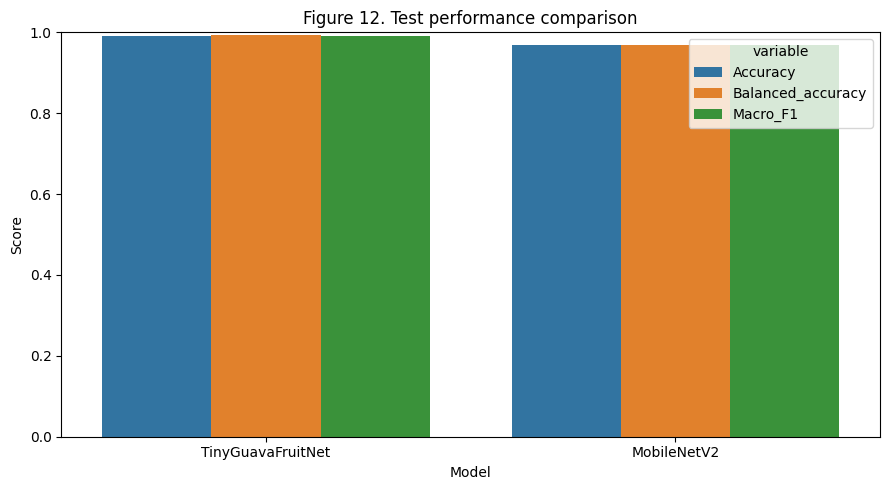

In [ ]:
def model_metrics_row(name, keras_model, yt, yp, prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(yt, yp),
        "Balanced_accuracy": balanced_accuracy_score(yt, yp),
        "Macro_precision": precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)[0],
        "Macro_recall": precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)[1],
        "Macro_F1": precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)[2],
        "MCC": matthews_corrcoef(yt, yp),
        "Parameters": keras_model.count_params()
    }
comparison_df = pd.DataFrame([
    model_metrics_row("TinyGuavaFruitNet", model, y_true, y_pred, y_prob),
    model_metrics_row("MobileNetV2", baseline, base_true, base_pred, base_prob)
])
display(comparison_df)
comparison_df.to_csv("Table10_model_comparison.csv", index=False)

plt.figure(figsize=(9,5))
plot_df = comparison_df.melt(id_vars="Model", value_vars=["Accuracy","Balanced_accuracy","Macro_F1"])
sns.barplot(data=plot_df, x="Model", y="value", hue="variable")
plt.ylabel("Score"); plt.ylim(0,1); plt.title("Figure 12. Test performance comparison")
plt.tight_layout(); plt.savefig("Fig12_model_comparison.png", dpi=300); plt.show()

## 9. Ablation study

Ablations should be trained using the same train/validation/test split and training protocol. The examples below test the effect of depthwise-separable convolutions and width. Because this is compute-intensive, run them after the main model and baseline are stable.

In [ ]:
# Optional ablation runner: execute when time/GPU budget permits.
RUN_ABLATIONS = False
ablation_specs = [
    ("TinyGuavaFruitNet_full", dict(use_bn=True, use_depthwise=True, width=1.0)),
    ("StandardConv", dict(use_bn=True, use_depthwise=False, width=1.0)),
    ("Width_0.5", dict(use_bn=True, use_depthwise=True, width=0.5)),
    ("Width_0.25", dict(use_bn=True, use_depthwise=True, width=0.25)),
    ("No_BN", dict(use_bn=False, use_depthwise=True, width=1.0)),
]
ablation_rows = []
if RUN_ABLATIONS:
    for name, kwargs in ablation_specs:
        abm = build_tinyguavafruitnet(**kwargs)
        abm.compile(optimizer=keras.optimizers.Adam(5e-4),
                    loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        h = abm.fit(train_ds, validation_data=val_ds, epochs=35,
                    class_weight=class_weight,
                    callbacks=[keras.callbacks.EarlyStopping(
                        monitor="val_loss", patience=7, restore_best_weights=True)],
                    verbose=1)
        yt, pr = collect_predictions(abm, test_ds)
        yp = pr.argmax(axis=1)
        row = model_metrics_row(name, abm, yt, yp, pr)
        row["Best_val_accuracy"] = max(h.history.get("val_accuracy", [np.nan]))
        ablation_rows.append(row)
        abm.save(f"{name}.keras")
    ablation_df = pd.DataFrame(ablation_rows)
    display(ablation_df)
    ablation_df.to_csv("Table11_ablation_results.csv", index=False)
else:
    print("Set RUN_ABLATIONS=True to train ablation variants.")

Set RUN_ABLATIONS=True to train ablation variants.


## 10. Robustness under image perturbations

This is a controlled corruption test, not a substitute for field validation. It applies brightness and Gaussian-noise perturbations to the held-out test images. Report these as synthetic robustness tests and do not call them real-world field results.

,Perturbation,Severity,Accuracy,Macro_F1
0,brightness,0.15,0.552356,0.499580
1,brightness,-0.15,0.850785,0.849986
2,noise,0.05,0.641361,0.645415
3,noise,0.10,0.403141,0.305299
4,contrast,0.25,0.921466,0.924307


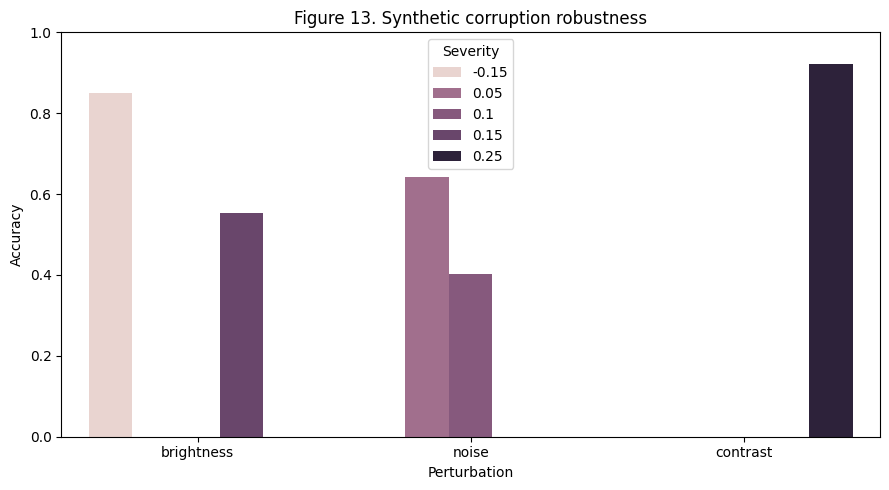

In [ ]:
def perturb_ds(frame, kind="brightness", severity=0.2):
    x = frame["path"].astype(str).values
    y = frame["label"].map(label_to_id).astype("int32").values
    ds = tf.data.Dataset.from_tensor_slices((x, y)).map(load_image, num_parallel_calls=AUTOTUNE)
    def perturb(img, label):
        if kind == "brightness":
            img = tf.clip_by_value(img + severity, 0.0, 1.0)
        elif kind == "noise":
            img = tf.clip_by_value(img + tf.random.normal(tf.shape(img), stddev=severity), 0.0, 1.0)
        elif kind == "contrast":
            img = tf.clip_by_value((img - 0.5) * (1.0 + severity) + 0.5, 0.0, 1.0)
        return img, label
    return ds.map(perturb, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

robust_rows = []
for kind, sev in [("brightness",0.15),("brightness",-0.15),("noise",0.05),("noise",0.10),("contrast",0.25)]:
    # Negative brightness is supported by the same clip operation.
    ds_corrupt = perturb_ds(test_df, kind=kind, severity=sev)
    yt, pr = collect_predictions(model, ds_corrupt)
    yp = pr.argmax(axis=1)
    robust_rows.append({"Perturbation": kind, "Severity": sev,
                        "Accuracy": accuracy_score(yt, yp),
                        "Macro_F1": precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)[2]})
robust_df = pd.DataFrame(robust_rows)
display(robust_df)
robust_df.to_csv("Table12_corruption_robustness.csv", index=False)

plt.figure(figsize=(9,5))
sns.barplot(data=robust_df, x="Perturbation", y="Accuracy", hue="Severity")
plt.ylim(0,1); plt.title("Figure 13. Synthetic corruption robustness")
plt.tight_layout(); plt.savefig("Fig13_robustness.png", dpi=300); plt.show()

## 11. TFLite conversion and INT8 quantization

The representative calibration dataset must come only from training images. The TFLite interpreter timings below are **host-side proxy measurements**; they are not microcontroller latency or energy measurements. For physical deployment claims, run the exported model on the named target board and measure latency, peak tensor arena, and power using a documented protocol.

In [ ]:
def representative_dataset():
    # Sample only training images for calibration.
    sample = train_df["path"].sample(min(200, len(train_df)), random_state=SEED).tolist()
    for p in sample:
        img = Image.open(p).convert("RGB").resize(IMG_SIZE)
        arr = np.asarray(img, dtype=np.float32) / 255.0
        yield [np.expand_dims(arr, axis=0)]

# Float TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_fp32 = converter.convert()
open("tinyguavafruitnet_fp32.tflite", "wb").write(tflite_fp32)

# Full integer quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8
tflite_int8 = converter.convert()
open("tinyguavafruitnet_int8.tflite", "wb").write(tflite_int8)

print("FP32 TFLite size (KB):", round(os.path.getsize("tinyguavafruitnet_fp32.tflite")/1024, 2))
print("INT8 TFLite size (KB):", round(os.path.getsize("tinyguavafruitnet_int8.tflite")/1024, 2))

Saved artifact at '/tmp/tmph3rh0e2k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 112, 112, 3), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  138124930496848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182294032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182293648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182294416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182294224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123191204368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182295184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182294992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182295376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182293456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138123182294

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


FP32 TFLite size (KB): 286.68
INT8 TFLite size (KB): 112.22


In [ ]:
def tflite_predict(interpreter, images):
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    in_detail, out_detail = input_details[0], output_details[0]
    outputs = []
    for img in images:
        x = np.expand_dims(img, 0)
        if in_detail["dtype"] == np.uint8:
            scale, zero = in_detail["quantization"]
            x = np.clip(np.round(x / scale + zero), 0, 255).astype(np.uint8)
        else:
            x = x.astype(in_detail["dtype"])
        interpreter.set_tensor(in_detail["index"], x)
        interpreter.invoke()
        y = interpreter.get_tensor(out_detail["index"])
        if out_detail["dtype"] == np.uint8:
            scale, zero = out_detail["quantization"]
            y = (y.astype(np.float32) - zero) * scale
        outputs.append(y.squeeze())
    return np.asarray(outputs)

# Materialize test images in the same order as test_df
test_images = []
for p in test_df["path"]:
    img = Image.open(p).convert("RGB").resize(IMG_SIZE)
    test_images.append(np.asarray(img, dtype=np.float32)/255.0)
test_images = np.asarray(test_images)
test_labels = test_df["label"].map(label_to_id).values

int8_interpreter = tf.lite.Interpreter(model_content=tflite_int8)
int8_interpreter.allocate_tensors()
int8_probs = tflite_predict(int8_interpreter, test_images)
int8_pred = int8_probs.argmax(axis=1)
int8_accuracy = accuracy_score(test_labels, int8_pred)
print("INT8 TFLite test accuracy:", int8_accuracy)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


INT8 TFLite test accuracy: 0.9764397905759162


In [ ]:
# Software-proxy latency: warm-up then repeated invocation on a sample.
def benchmark_tflite(model_content, sample_image, warmup=20, runs=200):
    interpreter = tf.lite.Interpreter(model_content=model_content, num_threads=1)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    x = np.expand_dims(sample_image, 0)
    if inp["dtype"] == np.uint8:
        scale, zero = inp["quantization"]
        x = np.clip(np.round(x / scale + zero), 0, 255).astype(np.uint8)
    else:
        x = x.astype(inp["dtype"])
    for _ in range(warmup):
        interpreter.set_tensor(inp["index"], x); interpreter.invoke()
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        interpreter.set_tensor(inp["index"], x); interpreter.invoke()
        times.append((time.perf_counter()-t0)*1000)
    return {"mean_ms": float(np.mean(times)), "median_ms": float(np.median(times)),
            "p95_ms": float(np.percentile(times,95)), "runs": runs, "warmup": warmup}

fp32_latency = benchmark_tflite(tflite_fp32, test_images[0])
int8_latency = benchmark_tflite(tflite_int8, test_images[0])
quant_table = pd.DataFrame([
    {"Variant":"TFLite FP32", "Size_KB":len(tflite_fp32)/1024,
     "Test_accuracy":accuracy_score(test_labels, model.predict(test_ds, verbose=0).argmax(axis=1)),
     **fp32_latency},
    {"Variant":"TFLite INT8", "Size_KB":len(tflite_int8)/1024,
     "Test_accuracy":int8_accuracy, **int8_latency}
])
display(quant_table)
quant_table.to_csv("Table13_quantization_and_proxy_latency.csv", index=False)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Variant,Size_KB,Test_accuracy,mean_ms,median_ms,p95_ms,runs,warmup
0,TFLite FP32,286.679688,0.992147,0.540241,0.472002,0.795533,200,20
1,TFLite INT8,112.218750,0.976440,0.898245,0.883783,1.031515,200,20


## 12. Resource, reproducibility, and publication tables

The analytical activation estimate below is only a rough upper bound based on tensor shapes and data type; it is not a measured TensorFlow Lite Micro tensor arena. Likewise, model file size is not total runtime RAM. Record runtime and hardware information from the actual Colab session.

In [ ]:
def runtime_metadata():
    gpus = tf.config.list_physical_devices("GPU")
    return {
        "Python": sys.version.split()[0],
        "TensorFlow": tf.__version__,
        "Platform": platform.platform(),
        "GPU_available": bool(gpus),
        "GPU_devices": str(gpus),
        "Image_size": f"{IMG_SIZE[0]}x{IMG_SIZE[1]}",
        "Batch_size": BATCH_SIZE,
        "Seed": SEED,
        "Train_images": len(train_df),
        "Validation_images": len(val_df),
        "Test_images": len(test_df),
        "Classes": " | ".join(class_names),
        "Model_parameters": model.count_params(),
        "Kaggle_dataset_slug": KAGGLE_DATASET
    }
meta_df = pd.DataFrame([runtime_metadata()])
display(meta_df.T.rename(columns={0:"Value"}))
meta_df.to_csv("Table14_runtime_reproducibility.csv", index=False)

# Export a compact summary of all major tables
summary_path = "MANUSCRIPT_RESULTS_SUMMARY.txt"
with open(summary_path, "w") as f:
    f.write("Guava fruit disease detection — measured results summary\n")
    f.write("="*58 + "\n")
    f.write(meta_df.to_string(index=False) + "\n\n")
    f.write("Overall metrics\n" + summary_metrics.to_string(index=False) + "\n\n")
    f.write("Classification report\n" + report_df.to_string() + "\n\n")
    f.write("Quantization/proxy latency\n" + quant_table.to_string(index=False) + "\n")
print("Wrote", summary_path)

,Value
Python,3.13.16
TensorFlow,2.21.0
Platform,Linux-6.6.159+-x86_64-with-glibc2.39
GPU_available,True
GPU_devices,"[PhysicalDevice(name='/physical_device:GPU:0',..."
Image_size,112x112
Batch_size,32
Seed,42
Train_images,2647
Validation_images,755


Wrote MANUSCRIPT_RESULTS_SUMMARY.txt


## 13. Suggested manuscript figure/table map

| Manuscript item | Notebook output |
|---|---|
| Figure 1 | `Fig01_class_distribution.png` |
| Figure 2 | `Fig02_sample_montage.png` |
| Figure 3 | `Fig03_image_dimensions.png` |
| Figure 4 | `Fig04_split_distribution.png` |
| Figure 5 | `Fig05_training_curves.png` |
| Figure 6 | `Fig06_confusion_matrix.png` |
| Figure 7 | `Fig07_normalized_confusion_matrix.png` |
| Figure 8 | `Fig08_roc_pr_curves.png` |
| Figure 9 | `Fig09_calibration.png` |
| Figure 10 | `Fig10_tsne_features.png` |
| Figure 11 | `Fig11_error_analysis.png` |
| Figure 12 | `Fig12_model_comparison.png` |
| Figure 13 | `Fig13_robustness.png` |
| Table 1 | `Table01_split_class_counts.csv` |
| Table 2 | `Table02_training_history.csv` |
| Table 3 | `Table03_classification_report.csv` |
| Table 4 | `Table04_overall_metrics.csv` |
| Tables 5–6 | ROC-AUC and average precision |
| Table 9 | Misclassified examples |
| Table 10 | Model comparison |
| Table 11 | Ablation results (if enabled) |
| Table 12 | Synthetic corruption robustness |
| Table 13 | INT8 quantization and host-side proxy latency |
| Table 14 | Runtime/reproducibility metadata |

The numbering can be adjusted to match the final manuscript. Figures/tables are created only after the relevant cells execute successfully.

## 14. Download generated outputs

Run this cell after the experiments finish. It packages the figures, CSV tables, model files, and summary into a ZIP archive.

In [ ]:
import glob, zipfile, os
files_to_package = []
patterns = [
    "Fig*.png", "Table*.csv", "*.tflite", "*.keras",
    "split_manifest.csv", "model_summary.txt", "MANUSCRIPT_RESULTS_SUMMARY.txt"
]
for pattern in patterns:
    files_to_package.extend(glob.glob(pattern))
files_to_package = sorted(set(files_to_package))
with zipfile.ZipFile("Guava_Fruit_Disease_Research_Outputs.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for f in files_to_package:
        if os.path.isfile(f):
            zf.write(f)
print("Packaged files:", len(files_to_package))
print("\n".join(files_to_package))
# In Colab, uncomment to download:
# from google.colab import files
# files.download("Guava_Fruit_Disease_Research_Outputs.zip")

Packaged files: 34
Fig01_class_distribution.png
Fig02_sample_montage.png
Fig03_image_dimensions.png
Fig04_split_distribution.png
Fig05_training_curves.png
Fig06_confusion_matrix.png
Fig07_normalized_confusion_matrix.png
Fig08_roc_pr_curves.png
Fig09_calibration.png
Fig10_tsne_features.png
Fig11_error_analysis.png
Fig12_model_comparison.png
Fig13_robustness.png
MANUSCRIPT_RESULTS_SUMMARY.txt
Table01_split_class_counts.csv
Table02_training_history.csv
Table03_classification_report.csv
Table04_overall_metrics.csv
Table05_classwise_roc_auc.csv
Table06_classwise_average_precision.csv
Table07_calibration_bins.csv
Table08_tsne_coordinates.csv
Table09_misclassified_examples.csv
Table10_model_comparison.csv
Table12_corruption_robustness.csv
Table13_quantization_and_proxy_latency.csv
Table14_runtime_reproducibility.csv
mobilenetv2_baseline.keras
model_summary.txt
split_manifest.csv
tinyguavafruitnet_best.keras
tinyguavafruitnet_final.keras
tinyguavafruitnet_fp32.tflite
tinyguavafruitnet_int8.tfl